# Decode the Bioreactor
## Understand the event log, build useful features, and predict unseen batches

This notebook is a complete, executable solution using the two competition CSV files. It explains what each measurement means, investigates the data engineering problems, validates models on entire unseen batches, and writes a submission in the supplied format.

**Prediction setting:** the initial biological state and the entire feed and volume record are supplied for each hidden batch. Predictions here are conditional on those supplied records. A live forecast made before future operator actions are known would require a different evaluation.

**Score honesty:** local validation is not a leaderboard submission. The reported leaderboard benchmark is 7.964% mean MAPE. No hidden labels or leaderboard feedback were used in this notebook. Model choices were developed on these 49 complete batches, so the final cross validation estimate can still contain model selection optimism.

Run the cells in order. Python, NumPy, pandas, SciPy, scikit-learn, Matplotlib and IPython are sufficient. A CPU is enough. Put the notebook and both CSV files in the same directory. The final submission cell is disabled by default.


## 1. Load the data and establish the prediction contract

The raw file mixes measurements and feed events. The template lists the 156 answers required by the competition. Its zeros are placeholders and must never enter model training as biological observations.

Units, the chemical identities of the substrate and byproduct, and the cell type are not stated in the CSVs. Axis labels therefore use file units. The additional briefing recording was not transcribed, so no assumptions have been attributed to it.


In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")

from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold

TARGETS = ["vcd", "tcd", "substrate", "byproduct"]
FEEDS = ["feed_substrate", "feed_b", "feed_c", "feed_d"]
SEED = 2026
N_FOLDS = 5
N_TREES = 300
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "medium", "savefig.bbox": "tight"})
COLORS = {"vcd": "#2166ac", "tcd": "#5c6bc0", "substrate": "#238b45", "byproduct": "#c76c19"}

def find_input(stem):
    for directory in [Path.cwd(), Path.cwd() / "upload", Path.cwd() / "data", Path('../input-data/Project 1 - DTB'), Path('/home/renku/work/input-data/Project 1 - DTB')]:
        matches = sorted(directory.glob(stem + "*.csv"))
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise ValueError(f"Several {stem} files found. Keep one intended input file.")
    raise FileNotFoundError(f"Put {stem}.csv beside this notebook, or in data/.")

raw_path = find_input("bioreaction_remaining")
template_path = find_input("bioreaction_template")
raw = pd.read_csv(raw_path, dtype={"batch_id": str})
template = pd.read_csv(template_path, dtype={"batch_id": str})
template_text = pd.read_csv(template_path, dtype={"batch_id": str, "elapsed_time": str})

provenance = pd.DataFrame([
    {"file": p.name, "bytes": p.stat().st_size,
     "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
    for p in [raw_path, template_path]
])
display(provenance)
print("Versions:", {"python": platform.python_version(), "numpy": np.__version__,
                    "pandas": pd.__version__, "scipy": scipy.__version__,
                    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__})
display(raw.head(8))


,file,bytes,sha256
0,bioreaction_remaining.csv,213241,476e717b31c0dee18e8d1601e78423d99798e917960dbe...
1,bioreaction_template.csv,4458,9919742ef694986ddd6bbab1cb83876347db5e942ea6f8...


Versions: {'python': '3.11.18', 'numpy': '2.4.6', 'pandas': '3.1.1', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False


### What do the biological columns mean?

| Column | Interpretation | Main question |
| --- | --- | --- |
| `vcd` | Concentration of viable, or living, cells | Are living cells growing or declining? |
| `tcd` | Concentration of all counted cells, including nonviable cells | Is the living fraction changing? |
| `substrate` | Measured nutrient concentration | How do feeding and consumption change availability? |
| `byproduct` | Measured metabolic byproduct concentration | How does the metabolism of the culture evolve? |
| Four feed columns | Amounts recorded at addition events | What was added and when? |
| `volume` | Measured amount of liquid in the vessel | How much can dilution explain? |

With compatible VCD and TCD units, viability is `100 * vcd / tcd`. Cell density is a concentration. It can fall when cell-free liquid is added even if no cells die. These are standard cell counting definitions; see the sources at the end.


In [2]:
required = {"batch_id", "elapsed_time", "volume", "to_predict", *TARGETS, *FEEDS}
assert required.issubset(raw.columns)
assert list(template.columns) == ["batch_id", "elapsed_time", *TARGETS]
assert not raw.duplicated(["batch_id", "elapsed_time"]).any()
assert raw.groupby("batch_id").elapsed_time.apply(lambda s: s.is_monotonic_increasing).all()
assert raw[TARGETS].notna().nunique(axis=1).eq(1).all()
assert raw.loc[raw.to_predict, TARGETS].isna().all().all()
assert template[TARGETS].eq(0).all().all()

observations = raw.loc[raw.volume.notna()].copy()
observations["slot"] = observations.groupby("batch_id").cumcount()
assert observations.groupby("batch_id").size().eq(14).all()
initial = observations.loc[observations.slot.eq(0)].set_index("batch_id")
assert initial[TARGETS].notna().all().all()
assert initial.elapsed_time.eq(0).all()

observed = observations.loc[observations[TARGETS].notna().all(axis=1)].copy()
assert observed[TARGETS].gt(0).all().all()
assert observed.tcd.ge(observed.vcd).all()
observed["viability"] = 100 * observed.vcd / observed.tcd

train_ids = np.array(sorted(observed.groupby("batch_id").size().loc[lambda s: s > 1].index))
hidden_ids = np.array(sorted(template.batch_id.unique()))
assert not set(train_ids) & set(hidden_ids)
assert len(train_ids) == 49 and len(hidden_ids) == 12
training_rows = observed.loc[observed.batch_id.isin(train_ids) & observed.slot.gt(0)].copy()
assert len(training_rows) == 637

row_type = pd.Series("unclassified", index=raw.index)
row_type.loc[raw[TARGETS].notna().all(axis=1)] = "Biology and volume"
row_type.loc[raw.to_predict] = "Hidden biology, volume supplied"
for feed in FEEDS:
    row_type.loc[raw[feed].notna()] = feed + " event"
assert not row_type.eq("unclassified").any()
assert (raw[FEEDS].notna().sum(axis=1) + raw.volume.notna()).eq(1).all()

display(row_type.value_counts().rename_axis("Row type").to_frame("Rows"))
display(pd.DataFrame({"Quantity": ["All event rows", "Complete batches", "Hidden batches",
                                   "Training prediction examples", "Required predictions"],
                      "Count": [len(raw), len(train_ids), len(hidden_ids),
                                len(training_rows), len(template)]}))


,Rows
Row type,
feed_c event,957
feed_b event,732
Biology and volume,698
feed_d event,183
"Hidden biology, volume supplied",156
feed_substrate event,132


,Quantity,Count
0,All event rows,2858
1,Complete batches,49
2,Hidden batches,12
3,Training prediction examples,637
4,Required predictions,156


**Discovery 1: missingness records different kinds of events.** The four biological variables are observed together, while feed additions occupy their own rows. A blank biological value on a feed row means no biological measurement was recorded. Zero filling would create fictitious cell deaths and nutrient depletion.

The following timeline shows why merging everything into one evenly sampled table requires care. Each mark is an actual recorded event.


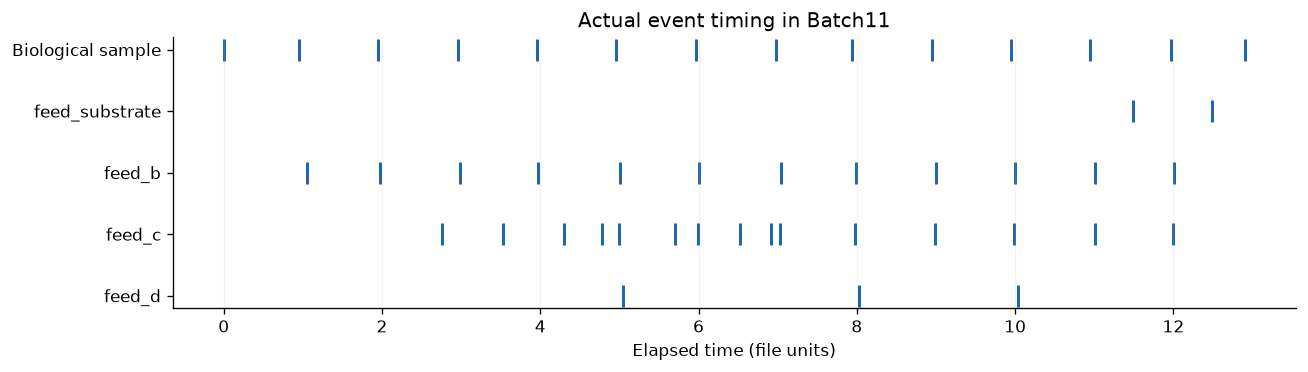

In [30]:
example_id = train_ids[2]
example = raw.loc[raw.batch_id.eq(example_id)]
fig, ax = plt.subplots(figsize=(11, 3.2))
lanes = [("Biological sample", example.vcd.notna())] + [(f, example[f].notna()) for f in FEEDS]
for lane, (label, mask) in enumerate(lanes):
    ax.scatter(example.loc[mask, "elapsed_time"], np.full(mask.sum(), lane),
               marker="|", s=160, linewidths=1.8, color="#2166ac")
ax.set(yticks=range(len(lanes)), yticklabels=[x[0] for x in lanes],
       xlabel="Elapsed time (file units)", title=f"Actual event timing in {example_id}")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()


**Event timeline vs. measured values.** The upper panel repeats the event marks. The lower panel shows the four biological targets (VCD, TCD, substrate, byproduct) measured at each biological-sample time point for the same example batch. Each coloured line connects the actual recorded values. This makes the sparse observation pattern visible: the lines are not a fitted model—they only connect the dots where a measurement was taken. Missing values on feed rows are simply skipped, so the line segments always span the interval between two biological measurements.


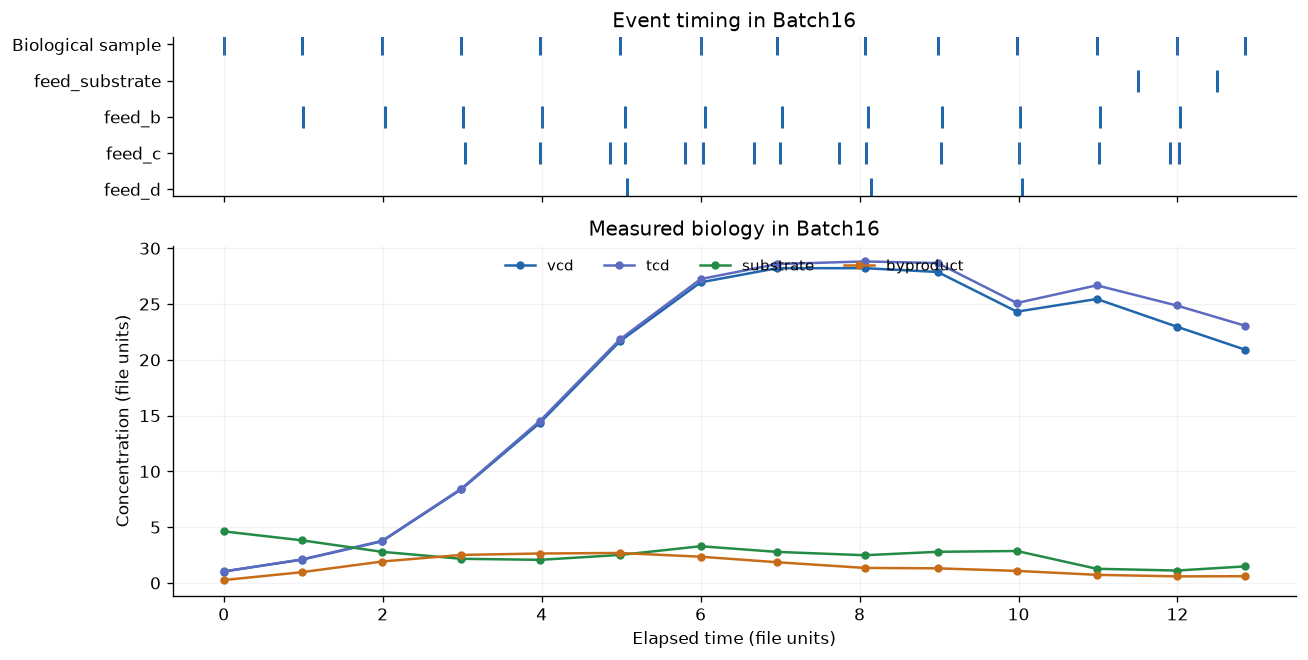

In [38]:
example_id = train_ids[6]
example = raw.loc[raw.batch_id.eq(example_id)]
bio = example.loc[example[TARGETS].notna().all(axis=1)].copy()

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True,
                                        gridspec_kw={'height_ratios': [1, 2.2]})

# --- top panel: event timeline (same style as before) ---
lanes = [("Biological sample", example.vcd.notna())] + [(f, example[f].notna()) for f in FEEDS]
for lane, (label, mask) in enumerate(lanes):
    ax_top.scatter(example.loc[mask, "elapsed_time"], np.full(mask.sum(), lane),
                   marker="|", s=160, linewidths=1.8, color="#2166ac")
ax_top.set(yticks=range(len(lanes)), yticklabels=[x[0] for x in lanes],
           title=f"Event timing in {example_id}")
ax_top.invert_yaxis()
ax_top.grid(axis="x", alpha=.15)

# --- bottom panel: target variable values over time ---
COLORS = {"vcd": "#2166ac", "tcd": "#5c6bc0", "substrate": "#238b45", "byproduct": "#c76c19"}
for target in TARGETS:
    ax_bottom.plot(bio["elapsed_time"], bio[target], marker="o", linewidth=1.5,
                   color=COLORS[target], label=target, markersize=4)
ax_bottom.set(xlabel="Elapsed time (file units)", ylabel="Concentration (file units)",
              title=f"Measured biology in {example_id}")
ax_bottom.legend(ncol=4, loc="upper center", fontsize=9, frameon=False)
ax_bottom.grid(axis="both", alpha=.15)
fig.tight_layout()
plt.show()


## 2. Read the biology before fitting a model

Each faint line below is one complete batch. The thicker line is the median at each observation slot. These plots are exploratory descriptions, not validation results.

VCD and TCD have a strong common growth pattern. Substrate has a pronounced late decline. Byproduct rises and then falls, so forcing it to increase monotonically would contradict the observations.


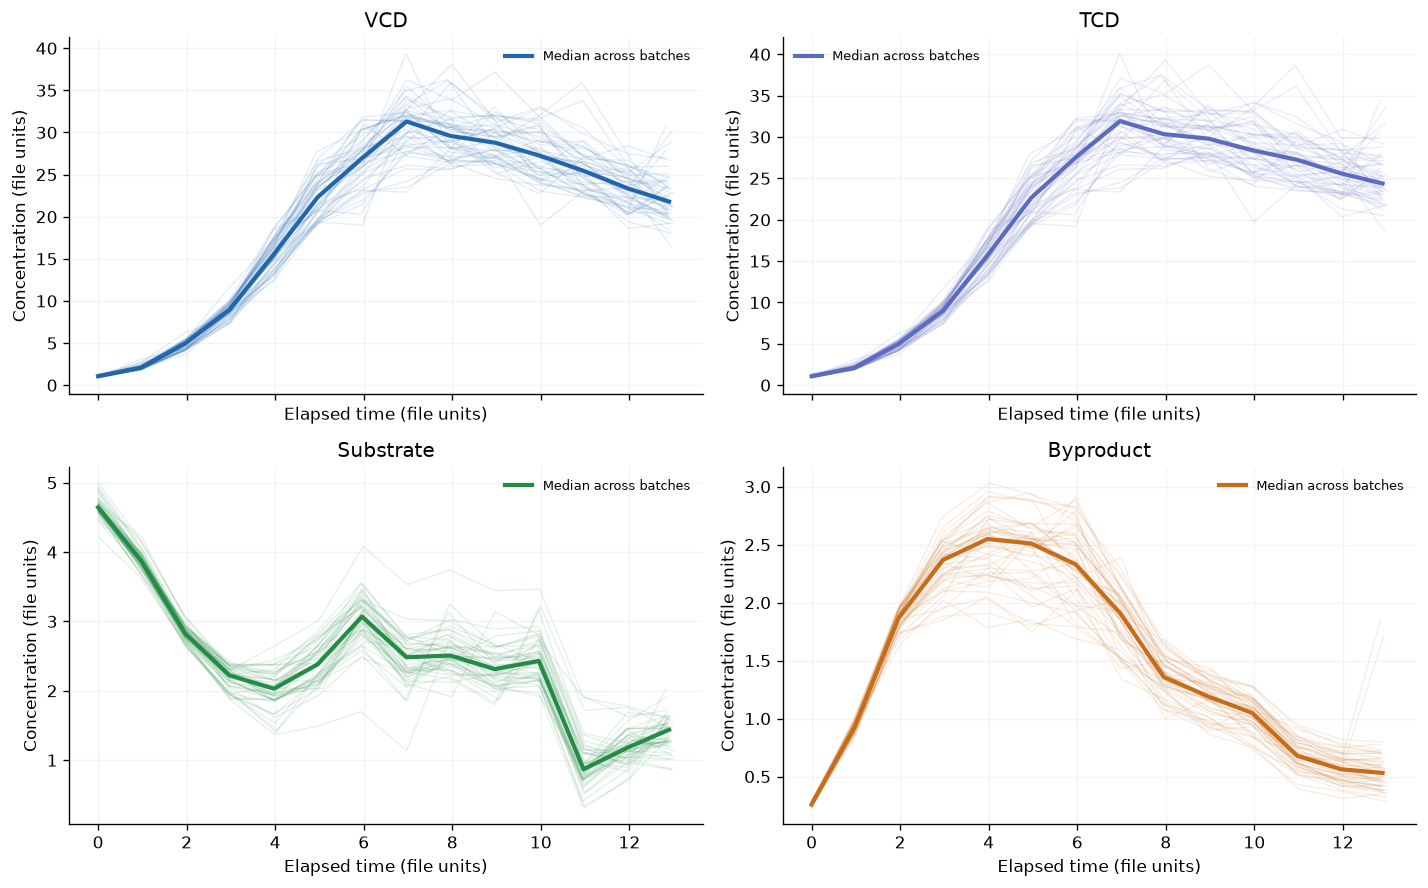

,vcd,tcd,substrate,byproduct,viability,volume
slot,,,,,,
0,1.078,1.093,4.662,0.264,98.738,10.452
4,15.610,15.749,2.008,2.490,99.126,10.938
7,30.663,31.321,2.420,1.877,97.914,12.837
10,27.326,28.617,2.482,1.034,95.497,15.282
11,25.863,27.499,0.925,0.688,94.082,15.723
13,22.469,25.163,1.394,0.580,89.248,16.802


Median initial viability: 98.96%
Median final viability: 89.73%


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for ax, target in zip(axes.flat, TARGETS):
    for _, group in observed.loc[observed.batch_id.isin(train_ids)].groupby("batch_id"):
        ax.plot(group.elapsed_time, group[target], color=COLORS[target], alpha=.12, linewidth=.8)
    summary = observed.loc[observed.batch_id.isin(train_ids)].groupby("slot")[["elapsed_time", target]].median()
    ax.plot(summary.elapsed_time, summary[target], color=COLORS[target], linewidth=2.5, label="Median across batches")
    ax.set(title=target.upper() if target in ["vcd", "tcd"] else target.capitalize(),
           ylabel="Concentration (file units)", xlabel="Elapsed time (file units)")
    ax.grid(alpha=.15)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

stage_summary = observed.loc[observed.batch_id.isin(train_ids)].groupby("slot")[TARGETS + ["viability", "volume"]].mean()
display(stage_summary.loc[[0, 4, 7, 10, 11, 13]].round(3))
print(f"Median initial viability: {observed.loc[observed.slot.eq(0), 'viability'].median():.2f}%")
print(f"Median final viability: {observed.loc[observed.slot.eq(13), 'viability'].median():.2f}%")


### A falling concentration does not automatically mean cell death

Suppose 1 litre contains 10 million living cells/mL. Adding 0.25 litres of cell-free feed gives 1.25 litres with 8 million living cells/mL immediately after mixing. The total number of cells is unchanged.

That is why volume and viability are useful alongside VCD. The next calculation investigates how closely recorded feeds explain the measured volume. It is an empirical bookkeeping feature. Interpreting it as a physical mass balance would require confirming that every feed amount is expressed in compatible volume units.


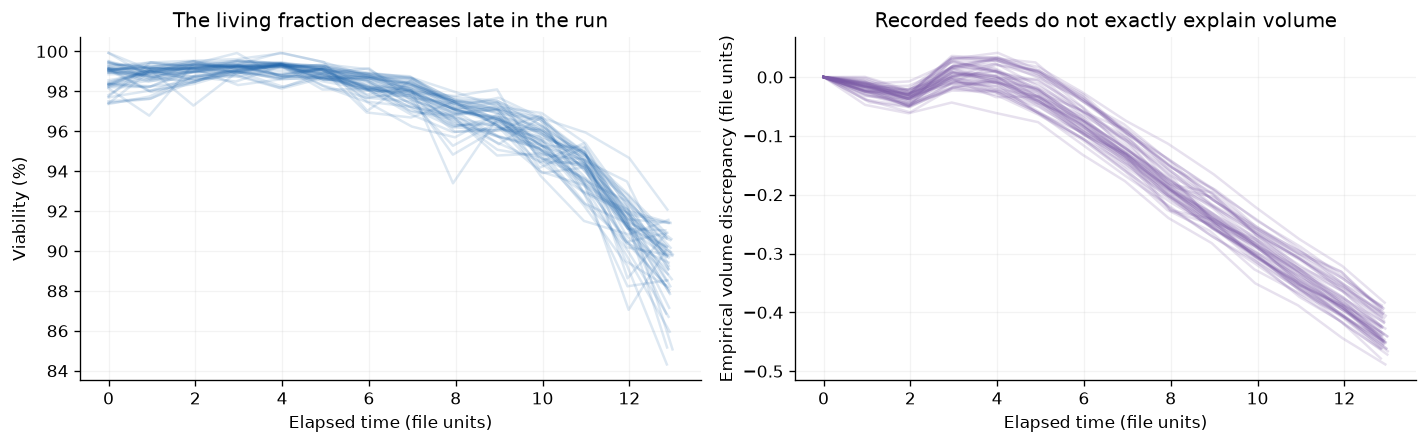

Final discrepancy: mean -0.4327, standard deviation 0.0264


In [5]:
def volume_bookkeeping(events):
    records = []
    for batch_id, batch in events.groupby("batch_id"):
        samples = batch.loc[batch.volume.notna()].sort_values("elapsed_time")
        start_volume = samples.volume.iloc[0]
        for slot, (_, sample) in enumerate(samples.iterrows()):
            additions = batch.loc[batch.elapsed_time.le(sample.elapsed_time), FEEDS].sum().sum()
            records.append({"batch_id": batch_id, "slot": slot, "time": sample.elapsed_time,
                            "volume": sample.volume, "recorded_additions": additions,
                            "volume_discrepancy": sample.volume - start_volume - additions})
    return pd.DataFrame(records)

bookkeeping = volume_bookkeeping(raw)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for _, group in observed.loc[observed.batch_id.isin(train_ids)].groupby("batch_id"):
    axes[0].plot(group.elapsed_time, group.viability, color="#2166ac", alpha=.15)
for _, group in bookkeeping.loc[bookkeeping.batch_id.isin(train_ids)].groupby("batch_id"):
    axes[1].plot(group.time, group.volume_discrepancy, color="#7b5aa6", alpha=.18)
axes[0].set(title="The living fraction decreases late in the run", ylabel="Viability (%)")
axes[1].set(title="Recorded feeds do not exactly explain volume", ylabel="Empirical volume discrepancy (file units)")
for ax in axes:
    ax.set_xlabel("Elapsed time (file units)")
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()

final_discrepancy = bookkeeping.loc[bookkeeping.batch_id.isin(train_ids) & bookkeeping.slot.eq(13), "volume_discrepancy"]
print(f"Final discrepancy: mean {final_discrepancy.mean():.4f}, standard deviation {final_discrepancy.std():.4f}")


**Discovery 2: recorded feed additions and observed volume do not form an exact closed balance.** Possible reasons include removals, unrecorded additions, sampling, different unit conventions or measurement effects. The files do not identify the cause. We retain the observed volume and test whether the discrepancy is useful statistically.

**Discovery 3: MAPE makes low substrate values important.** A 0.2 error when the true value is 4.0 is 5%. The same absolute error when the true value is 0.5 is 40%. All observed targets are positive, so no arbitrary denominator clipping is needed for local scoring.


In [6]:
def mape_percent(truth, prediction):
    truth = np.asarray(truth, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    assert truth.shape == prediction.shape
    assert np.isfinite(truth).all() and np.isfinite(prediction).all()
    assert (truth > 0).all()
    return 100 * np.mean(np.abs(prediction - truth) / truth, axis=0)

print("Same 0.2 absolute error:")
print("At 4.0:", float(mape_percent(np.array([4.0]), np.array([4.2]))), "%")
print("At 0.5:", float(mape_percent(np.array([0.5]), np.array([0.7]))), "%")
display(training_rows.groupby("slot")["substrate"].agg(["min", "median", "max"]).round(3))


Same 0.2 absolute error:
At 4.0: 5.000000000000004 %
At 0.5: 39.99999999999999 %


,min,median,max
slot,,,
1,3.581,3.881,4.231
2,2.641,2.823,3.114
3,1.844,2.223,2.430
4,1.369,2.030,2.641
5,1.488,2.382,3.012
6,1.699,3.071,4.082
7,1.140,2.483,3.529
8,1.912,2.509,3.741
9,1.801,2.312,3.444


## 3. Fix the submission alignment before modeling

**Discovery 4: visually identical timestamps are not always identical floating point keys.** The template rounds timestamps differently from the raw prediction rows. A direct exact merge misses most requested predictions.

We pair rows within each batch by their sorted observation order, assert that the paired timestamps are almost identical, and preserve the original template values and row order in the exported CSV. This uses the verified one-to-one sampling structure, not an unchecked approximate join.


In [7]:
hidden_raw = observations.loc[observations.to_predict].copy()
exact_matches = template[["batch_id", "elapsed_time"]].merge(
    hidden_raw[["batch_id", "elapsed_time"]], on=["batch_id", "elapsed_time"], how="inner")

def align_template(template_frame, raw_prediction_rows):
    query = template_frame[["batch_id", "elapsed_time"]].copy()
    query["raw_index"] = -1
    query["slot"] = -1
    max_difference = 0.0
    assert not query.duplicated(["batch_id", "elapsed_time"]).any()
    assert set(query.batch_id) == set(raw_prediction_rows.batch_id)
    for batch_id, requested in query.groupby("batch_id", sort=False):
        requested = requested.sort_values("elapsed_time")
        available = raw_prediction_rows.loc[raw_prediction_rows.batch_id.eq(batch_id)].sort_values("elapsed_time")
        assert len(requested) == len(available)
        difference = np.abs(requested.elapsed_time.to_numpy() - available.elapsed_time.to_numpy())
        assert np.all(difference < 1e-7), f"Timestamp mismatch in {batch_id}"
        max_difference = max(max_difference, difference.max())
        query.loc[requested.index, "raw_index"] = available.index.to_numpy()
        query.loc[requested.index, "slot"] = available.slot.to_numpy()
    assert query.raw_index.is_unique and query.raw_index.ge(0).all()
    return query, max_difference

hidden_queries, largest_time_difference = align_template(template, hidden_raw)
print(f"Exact raw/template matches: {len(exact_matches)} of {len(template)}")
print(f"Largest paired timestamp difference: {largest_time_difference:.12g}")
print(f"Verified prediction rows: {len(hidden_queries)}")
display(hidden_queries.head())


Exact raw/template matches: 2 of 156
Largest paired timestamp difference: 4.44669900901e-09
Verified prediction rows: 156


,batch_id,elapsed_time,raw_index,slot
0,Batch5,0.965972,192,1
1,Batch5,1.948611,194,2
2,Batch5,2.940278,197,3
3,Batch5,3.919444,200,4
4,Batch5,4.924306,203,5


## 4. Build features from information the competition actually supplies

The model can use initial biology, query time, and supplied feed and volume records. Later biological targets are labels, not features. To make this separation explicit, we create an input-only copy that erases every biological value after the initial sample.

Some feeds occur shortly after a biological sample. They can carry information about the run, but using them is justified here only because the full schedules are supplied for hidden batches. Predictive association does not show that a particular feed caused the observed change.


In [8]:
public_inputs = raw.copy()
initial_indices = observations.loc[observations.slot.eq(0)].index
public_inputs.loc[~public_inputs.index.isin(initial_indices), TARGETS] = np.nan
assert public_inputs[TARGETS].notna().all(axis=1).sum() == 61

training_queries = training_rows[["batch_id", "elapsed_time", "slot"]].copy()
truth = training_rows[TARGETS].to_numpy()
groups = training_rows.batch_id.to_numpy()
print("Noninitial biological labels available to feature builders:",
      public_inputs.loc[~public_inputs.index.isin(initial_indices), TARGETS].notna().sum().sum())


Noninitial biological labels available to feature builders: 0


### Batch signatures: a small summary of the run

Initial cell density, initial nutrients, initial volume, total additions and the first addition time describe the starting state and supplied operating schedule. These summaries are independent of later target measurements.


In [9]:
def batch_signatures(raw):
    """Summarize only information provided for every competition batch."""
    rows=[]
    for batch, events in raw.groupby('batch_id', sort=False):
        events=events.sort_values('elapsed_time')
        initial=events.loc[events[TARGETS].notna().all(axis=1)].iloc[0]
        row={'batch_id':batch}
        for target in TARGETS + ['volume']:
            row['init_'+target]=float(initial[target])
        row['initial_viability']=float(np.log(initial.vcd/initial.tcd))
        for feed in FEEDS:
            additions=events.loc[events[feed].notna()]
            row[feed+'_sum']=float(additions[feed].sum())
            row[feed+'_first']=float(additions.elapsed_time.min()) if len(additions) else 0.0
        row['feed_c_count']=int(events.feed_c.notna().sum())
        rows.append(row)
    return pd.DataFrame(rows).set_index('batch_id')


In [10]:
signatures = batch_signatures(public_inputs)
display(signatures.head().round(4))
print("Batch signatures:", signatures.shape)


,init_vcd,init_tcd,init_substrate,init_byproduct,init_volume,initial_viability,feed_substrate_sum,feed_substrate_first,feed_b_sum,feed_b_first,feed_c_sum,feed_c_first,feed_d_sum,feed_d_first,feed_c_count
batch_id,,,,,,,,,,,,,,,
Batch1,0.9797,0.9853,4.5072,0.2418,10.5007,-0.0057,0.1579,11.5128,6.4027,1.0150,0.0214,2.7230,0.0437,5.0457,16
Batch2,1.0454,1.0518,4.5795,0.2401,10.3879,-0.0061,0.1297,11.5072,6.8461,1.1422,0.0213,2.8690,0.0441,5.0731,16
Batch3,1.1341,1.1443,4.6051,0.2588,10.3904,-0.0090,0.1609,11.4600,6.6696,0.9857,0.0274,2.3267,0.0437,5.0474,23
Batch4,1.1563,1.1662,4.5655,0.2907,10.5064,-0.0086,0.1610,11.4862,6.7194,1.0126,0.0179,3.0811,0.0440,5.0301,12
Batch5,1.3223,1.3425,4.7431,0.3022,10.5053,-0.0152,0.1623,11.4762,6.9036,0.9866,0.0180,2.6422,0.0446,5.0094,12


Batch signatures: (61, 15)


### Match feed events to the actual sampling intervals

**Discovery 5: rounding feed times can create false differences.** Additions at 11.48 and 11.51 may occur in comparable parts of a run, but rounding assigns them to different integers. We keep event timing and assign each feed to the interval between actual samples.

For substrate, features describe the nearby intervals: amount added, event count and position within the interval. Early feed amounts and the supplied late substrate additions provide additional context. Missing additions within a verified interval represent no recorded event, so a zero event sum is appropriate there.


In [11]:
def make_interval_features(raw, queries):
    """Summarize feed events between actual sample times, never rounded days."""
    contexts = {}
    for batch_id, batch in raw.groupby('batch_id'):
        batch = batch.sort_values('elapsed_time')
        initial = batch.iloc[0]
        samples = batch.loc[batch.volume.notna()]
        times = samples.elapsed_time.to_numpy()
        context = {'times': times, 'volumes': samples.volume.to_numpy(),
                   'initial': initial, 'intervals': {}, 'totals': {}}
        for feed in ['feed_substrate', 'feed_b']:
            events = batch.loc[batch[feed].notna()]
            event_times = events.elapsed_time.to_numpy()
            amounts = events[feed].to_numpy()
            context['totals'][feed] = (amounts.sum(), len(amounts))
            for slot in range(len(times) - 1):
                mask = (event_times >= times[slot]) & (event_times < times[slot + 1])
                position = ((event_times[mask].mean() - times[slot]) /
                            (times[slot + 1] - times[slot])) if mask.any() else 0.
                context['intervals'][feed, slot] = (amounts[mask].sum(), mask.sum(), position)
        contexts[batch_id] = context

    rows = []
    for _, query in queries.iterrows():
        c = contexts[query.batch_id]
        times, initial = c['times'], c['initial']
        slot = int(np.argmin(abs(times - query.elapsed_time)))
        if abs(times[slot] - query.elapsed_time) > 1e-5:
            raise ValueError('Query is not aligned with a supplied sample time.')
        if slot == 0:
            raise ValueError('This model predicts times after the initial sample.')
        row = {'slot': slot, 'time': query.elapsed_time,
               'initial_vcd': initial.vcd, 'initial_substrate': initial.substrate,
               'initial_volume': initial.volume,
               'volume_ratio': c['volumes'][slot] / initial.volume,
               'interval_duration': times[slot] - times[slot - 1]}
        interval = lambda feed, j: c['intervals'].get((feed, j), (0., 0, 0.))
        for j in [1, 2]:
            row[f'feed_b_int{j}_amount'] = interval('feed_b', j)[0]
        row['feed_substrate_total'], row['feed_substrate_count'] = c['totals']['feed_substrate']
        for j in [11, 12]:
            row[f'feed_substrate_int{j}_amount'] = interval('feed_substrate', j)[0]
        for feed in ['feed_substrate', 'feed_b']:
            for offset in [-2, -1, 0, 1]:
                values = interval(feed, slot + offset)
                for kind, value in zip(['amount', 'count', 'time'], values):
                    row[f'{feed}_local{offset}_{kind}'] = value
        rows.append(row)
    return pd.DataFrame(rows, index=queries.index)


In [12]:
interval_train = make_interval_features(public_inputs, training_queries)
interval_hidden = make_interval_features(public_inputs, hidden_queries)
assert np.isfinite(interval_train.to_numpy()).all()
assert np.isfinite(interval_hidden.to_numpy()).all()
display(interval_train.head().round(4))
print("Interval features:", interval_train.shape[1], "including the sampling slot")


,slot,time,initial_vcd,initial_substrate,initial_volume,volume_ratio,interval_duration,feed_b_int1_amount,feed_b_int2_amount,feed_substrate_total,...,feed_b_local-2_time,feed_b_local-1_amount,feed_b_local-1_count,feed_b_local-1_time,feed_b_local0_amount,feed_b_local0_count,feed_b_local0_time,feed_b_local1_amount,feed_b_local1_count,feed_b_local1_time
1,1,0.9965,0.9797,4.5072,10.5007,0.9994,0.9965,0.0622,0.1361,0.1579,...,0.0000,0.0000,0,0.0000,0.0622,1,0.0187,0.1361,1,0.0608
3,2,1.9847,0.9797,4.5072,10.5007,1.0035,0.9882,0.0622,0.1361,0.1579,...,0.0000,0.0622,1,0.0187,0.1361,1,0.0608,0.2719,1,0.0137
6,3,2.9674,0.9797,4.5072,10.5007,1.0186,0.9826,0.0622,0.1361,0.1579,...,0.0187,0.1361,1,0.0608,0.2719,1,0.0137,0.4940,1,0.0224
9,4,3.9708,0.9797,4.5072,10.5007,1.0425,1.0035,0.0622,0.1361,0.1579,...,0.0608,0.2719,1,0.0137,0.4940,1,0.0224,0.7758,1,0.0473
13,5,4.9639,0.9797,4.5072,10.5007,1.0873,0.9931,0.0622,0.1361,0.1579,...,0.0137,0.4940,1,0.0224,0.7758,1,0.0473,0.6605,1,0.0403


Interval features: 37 including the sampling slot


### Let a batch adjustment change with process stage

For byproduct, early and final volume discrepancies add a useful signature. A stage interaction means that the effect of a signature can vary as the run progresses. For example, the same discrepancy need not have the same association with byproduct near its peak and near the end.

The following helper calculates these empirical features. It makes no assumption about the chemistry of any feed.


In [13]:
def byproduct_signatures(raw):
    result=batch_signatures(raw)
    for batch,events in raw.groupby('batch_id',sort=False):
        events=events.sort_values('elapsed_time')
        samples=events[events.volume.notna()].reset_index(drop=True)
        volume=samples.volume.to_numpy();time=samples.elapsed_time.to_numpy()
        additions=np.array([events.loc[events.elapsed_time<=t,FEEDS].sum().sum() for t in time])
        residual=volume-volume[0]-additions
        for day in [2,3,4,5]:
            result.loc[batch,'early_residual_'+str(day)]=residual[day]
        result.loc[batch,'final_residual']=residual[-1]
    return result


In [16]:
byproduct_inputs = byproduct_signatures(public_inputs)
display(byproduct_inputs[["early_residual_2", "early_residual_3", "early_residual_4",
                         "early_residual_5", "final_residual"]].head().round(4))

# A direct leakage check: altering every later target must not alter predictors.
tampered = raw.copy()
tampered.loc[~tampered.index.isin(initial_indices), TARGETS] = 123456.0
pd.testing.assert_frame_equal(batch_signatures(tampered), signatures)
pd.testing.assert_frame_equal(byproduct_signatures(tampered), byproduct_inputs)
pd.testing.assert_frame_equal(make_interval_features(tampered, training_queries), interval_train)
print("Verified: later biological measurements cannot affect these features.")


,early_residual_2,early_residual_3,early_residual_4,early_residual_5,final_residual
batch_id,,,,,
Batch1,-0.0259,-0.0040,-0.0261,-0.0508,-0.4661
Batch2,-0.0317,0.0279,0.0276,0.0087,-0.3919
Batch3,-0.0219,0.0101,-0.0020,-0.0044,-0.4177
Batch4,-0.0393,0.0084,-0.0053,-0.0445,-0.4405
Batch5,-0.0223,0.0147,-0.0040,-0.0339,-0.4518


Verified: later biological measurements cannot affect these features.


## 5. Fit models that match the patterns in the data

| Component | Model | Why it is useful here |
| --- | --- | --- |
| Baseline | Median trajectory by observation slot | Tests whether a model improves on the shared pattern alone |
| VCD and TCD | Smooth shared curve with a small batch adjustment | Cell curves share a strong overall shape |
| Substrate | Small tree ensemble at each sampling slot | Local feeding relationships change through the run |
| Byproduct | Smooth curve, volume signatures and stage interactions | Both curve level and shape vary across batches |

The final models predict logarithms, then exponentiate. Predictions are positive, and relative differences receive more attention than they would under raw squared error. Log fitting is helpful for percentage error, but it is not exactly the same loss as MAPE.

The smooth models use a spline to draw a flexible time curve and ridge regularization to keep batch adjustments modest. Robust reweighting reduces the influence of unusually large residuals without deleting the corresponding observations. Every observation remains in validation.


In [17]:
class MedianTrajectory:
    """A simple common trajectory, learned only from training batches."""
    def fit(self, data, batch_ids):
        rows = data.loc[data.batch_id.isin(batch_ids) & data.volume.notna()].copy()
        rows["slot"] = rows.groupby("batch_id").cumcount()
        self.profile = rows.groupby("slot")[["elapsed_time", *TARGETS]].median()
        return self

    def predict(self, queries):
        return np.column_stack([
            np.interp(queries.elapsed_time, self.profile.elapsed_time, self.profile[target])
            for target in TARGETS
        ])


### Cell model

The equation is `log(cell density) = smooth time curve + batch adjustment`.

With only 49 independent complete runs, this deliberately shares information across times. The robust cutoff controls how strongly an unusual log residual is downweighted. It is a statistical setting, not a biological threshold.


In [18]:
class SharedCurveRegressor:
    """Predict log concentration as a smooth time curve plus a run adjustment.

    Robust reweighting reduces the influence of unusually noisy observations.
    The feature coefficients are constant in time: a deliberate low-complexity
    choice for only 49 independent training batches.
    """
    def __init__(self, n_knots=16, alpha=0.01, robust_cutoff=0.05, iterations=10, couple_cells=False):
        self.n_knots=n_knots
        self.alpha=alpha
        self.robust_cutoff=robust_cutoff
        self.iterations=iterations
        self.couple_cells=couple_cells

    def _design(self, queries, signatures, fit=False):
        batch_values=signatures.loc[queries.batch_id, self.feature_names].to_numpy()
        time=queries[['elapsed_time']].to_numpy()
        if fit:
            self.scaler=StandardScaler().fit(batch_values)
            self.time_basis=SplineTransformer(n_knots=self.n_knots, degree=3,
                                               include_bias=True).fit(time)
        return np.column_stack([self.time_basis.transform(time),
                                self.scaler.transform(batch_values)])

    def fit(self, raw, train_batches, targets=('vcd','tcd')):
        self.targets=list(targets)
        self.feature_names=['init_vcd','init_substrate','init_byproduct','init_volume',
                            'initial_viability']+[f+'_sum' for f in FEEDS]+[
                            f+'_first' for f in FEEDS]+['feed_c_count']
        train_raw=raw.loc[raw.batch_id.isin(train_batches)].copy()
        signatures=batch_signatures(train_raw)
        observed=train_raw.loc[(train_raw.elapsed_time>0) &
                               train_raw[self.targets].notna().all(axis=1)].copy()
        design=self._design(observed,signatures,fit=True)
        self.models={}
        for target in self.targets:
            response=np.log(observed[target].to_numpy())
            weight=np.ones(len(response))
            model=Ridge(alpha=self.alpha,fit_intercept=False)
            for _ in range(self.iterations):
                model.fit(design,response,sample_weight=weight)
                residual=np.abs(response-model.predict(design))
                weight=np.minimum(1.0,self.robust_cutoff/np.maximum(residual,1e-10))
            self.models[target]=model
        if self.couple_cells and 'vcd' in self.targets and 'tcd' in self.targets:
            response=np.log(observed.tcd.to_numpy()/observed.vcd.to_numpy())
            weight=np.ones(len(response))
            self.viability_model=Ridge(alpha=self.alpha,fit_intercept=False)
            for _ in range(self.iterations):
                self.viability_model.fit(design,response,sample_weight=weight)
                residual=np.abs(response-self.viability_model.predict(design))
                weight=np.minimum(1.0,0.01/np.maximum(residual,1e-10))
        return self

    def predict(self, raw, queries):
        signatures=batch_signatures(raw.loc[raw.batch_id.isin(queries.batch_id.unique())])
        design=self._design(queries,signatures)
        result=pd.DataFrame({target:np.exp(model.predict(design))
                             for target,model in self.models.items()},index=queries.index)
        if self.couple_cells and 'vcd' in self.targets and 'tcd' in self.targets:
            log_ratio=np.maximum(self.viability_model.predict(design),0.0)
            result['tcd']=result.vcd*np.exp(log_ratio)
        return result


### Substrate model

ExtraTrees averages many small randomized decision trees. Here there is one ensemble per observation slot. Every ensemble learns from one example per training batch, using a compact set of feeding and volume features. The tree count, seed and feature order are fixed for reproducibility.


In [19]:
class IntervalMetaboliteModel(RegressorMixin, BaseEstimator):
    """Small tree ensemble per sampling slot, trained on log concentrations."""
    def __init__(self, min_samples_leaf=1, n_estimators=300, random_state=17):
        self.min_samples_leaf = min_samples_leaf
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        self.columns_ = [column for column in X if column != 'slot']
        self.models_ = {}
        values = np.asarray(y)
        if np.any(values <= 0):
            raise ValueError('Log concentration model requires positive labels.')
        for slot in sorted(X.slot.unique()):
            mask = X.slot.to_numpy() == slot
            model = ExtraTreesRegressor(n_estimators=self.n_estimators,
                min_samples_leaf=self.min_samples_leaf, max_features=.7,
                random_state=self.random_state, n_jobs=2)
            model.fit(X.loc[mask, self.columns_], np.log(values[mask]))
            self.models_[slot] = model
        return self

    def predict(self, X):
        predictions = np.empty(len(X))
        for slot in X.slot.unique():
            mask = X.slot.to_numpy() == slot
            predictions[mask] = np.exp(self.models_[slot].predict(X.loc[mask, self.columns_]))
        return predictions


### Byproduct model

This model combines a smooth typical trajectory with batch signatures and their interactions with elapsed time. The time curve is penalized less strongly than the batch effects so that the model can learn the shared rise and fall without allowing large arbitrary batch corrections.


In [20]:
class ByproductCurve:
    """Pooled smooth shape with regularized run adjustments and phase effects."""
    def __init__(self,n_knots=12,alpha=30,robust_cutoff=0.1,phase=True):
        self.n_knots=n_knots;self.alpha=alpha
        self.robust_cutoff=robust_cutoff;self.phase=phase
        self.feature_names=['init_vcd','init_substrate','init_byproduct','init_volume','initial_viability']+[
            f+'_sum' for f in FEEDS]+['feed_c_count','early_residual_2','early_residual_3','early_residual_4','early_residual_5','final_residual']

    def _design(self,queries,signatures,fit=False):
        x=signatures.loc[queries.batch_id,self.feature_names].to_numpy()
        time=queries[['elapsed_time']].to_numpy()
        if fit:
            self.scaler=StandardScaler().fit(x)
            self.basis=SplineTransformer(n_knots=self.n_knots,degree=3,include_bias=True).fit(time)
        z=self.scaler.transform(x)
        parts=[self.basis.transform(time)*100,z]
        if self.phase:parts.append(z*(time-7)/6)
        return np.column_stack(parts)

    def fit(self,raw,train_batches):
        data=raw.loc[raw.batch_id.isin(train_batches)]
        samples=data.loc[(data.elapsed_time>0)&data.byproduct.notna()]
        design=self._design(samples,byproduct_signatures(data),fit=True)
        target=np.log(samples.byproduct.to_numpy());weight=np.ones(len(target))
        self.model=Ridge(alpha=self.alpha,fit_intercept=False)
        for step in range(10):
            self.model.fit(design,target,sample_weight=weight)
            residual=np.abs(target-self.model.predict(design))
            weight=np.minimum(1,self.robust_cutoff/np.maximum(residual,1e-10))
        return self

    def predict(self,raw,queries):
        design=self._design(queries,byproduct_signatures(raw.loc[raw.batch_id.isin(queries.batch_id)]))
        return np.exp(self.model.predict(design))


## 6. Validate on complete unseen batches

All 13 prediction rows from a batch stay in the same fold. The initial biological state and supplied input schedules remain available, exactly as for the competition's hidden batches. Scalers, splines and model coefficients are fitted inside each training fold.

This is a fivefold group evaluation, with KFold applied to the list of unique batch IDs. It produces one prediction for every training example from a model that did not train on that batch. The initial sample is excluded from scoring because the competition already supplies it.

We also test a byproduct model without stage interactions. This checks whether the interesting volume signature improves prediction in a useful way.

The supplied leaderboard notebook exposes a submission API but not the server's metric implementation. Local scoring uses the standard percentage MAPE for each target and the unweighted mean of the four target scores, consistent with the displayed benchmark.


In [21]:
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(train_ids))
oof = np.full_like(truth, np.nan)
baseline_oof = np.full_like(truth, np.nan)
byproduct_without_phase = np.full(len(truth), np.nan)
fold_numbers = np.full(len(truth), -1)
fold_results = []

for fold, (fit_positions, valid_positions) in enumerate(folds, start=1):
    fit_ids, valid_ids = train_ids[fit_positions], train_ids[valid_positions]
    fit_mask = np.isin(groups, fit_ids)
    valid_mask = np.isin(groups, valid_ids)
    queries = training_queries.loc[valid_mask]
    assert not set(fit_ids) & set(valid_ids)

    baseline = MedianTrajectory().fit(raw, fit_ids)
    baseline_oof[valid_mask] = baseline.predict(queries)

    cells_model = SharedCurveRegressor(n_knots=12, alpha=.01, robust_cutoff=.05)
    cells_model.fit(raw, fit_ids)
    oof[valid_mask, :2] = cells_model.predict(public_inputs, queries)[["vcd", "tcd"]].to_numpy()

    substrate_model = IntervalMetaboliteModel(n_estimators=N_TREES, min_samples_leaf=1)
    substrate_model.fit(interval_train.loc[fit_mask], truth[fit_mask, 2])
    oof[valid_mask, 2] = substrate_model.predict(interval_train.loc[valid_mask])

    byproduct_model = ByproductCurve(n_knots=12, alpha=30, robust_cutoff=.1, phase=True)
    byproduct_model.fit(raw, fit_ids)
    oof[valid_mask, 3] = byproduct_model.predict(public_inputs, queries)

    no_phase = ByproductCurve(n_knots=12, alpha=30, robust_cutoff=.1, phase=False)
    no_phase.fit(raw, fit_ids)
    byproduct_without_phase[valid_mask] = no_phase.predict(public_inputs, queries)

    # The consistency adjustment is applied in validation and final prediction alike.
    oof[valid_mask, 1] = np.maximum(oof[valid_mask, 1], oof[valid_mask, 0])
    fold_numbers[valid_mask] = fold
    scores = mape_percent(truth[valid_mask], oof[valid_mask])
    fold_results.append({"fold": fold, "batches": len(valid_ids),
                         **dict(zip(TARGETS, scores)), "mean_mape": scores.mean()})
    print(f"Fold {fold}: {len(valid_ids)} unseen batches, mean MAPE {scores.mean():.3f}%")

assert np.isfinite(oof).all() and np.isfinite(baseline_oof).all()
assert (fold_numbers > 0).all()
model_scores = mape_percent(truth, oof)
baseline_scores = mape_percent(truth, baseline_oof)
score_table = pd.DataFrame([baseline_scores, model_scores],
                          index=["Median trajectory baseline", "Final model"], columns=TARGETS)
score_table["mean_mape"] = score_table.mean(axis=1)
display(score_table.round(3))
display(pd.DataFrame(fold_results).round(3))
print("Byproduct without stage interactions:", round(float(mape_percent(truth[:, 3], byproduct_without_phase)), 3), "%")
print("Byproduct with stage interactions:", round(float(model_scores[3]), 3), "%")


Fold 1: 10 unseen batches, mean MAPE 7.495%
Fold 2: 10 unseen batches, mean MAPE 7.596%
Fold 3: 10 unseen batches, mean MAPE 7.883%
Fold 4: 10 unseen batches, mean MAPE 7.258%
Fold 5: 9 unseen batches, mean MAPE 7.813%


,vcd,tcd,substrate,byproduct,mean_mape
Median trajectory baseline,8.998,9.050,11.653,11.688,10.347
Final model,6.925,6.944,8.035,8.515,7.605


,fold,batches,vcd,tcd,substrate,byproduct,mean_mape
0,1,10,6.980,6.992,8.315,7.692,7.495
1,2,10,6.375,6.378,8.809,8.822,7.596
2,3,10,7.462,7.575,6.575,9.923,7.883
3,4,10,6.836,6.784,9.039,6.374,7.258
4,5,9,6.975,6.999,7.372,9.905,7.813


Byproduct without stage interactions: 9.506 %
Byproduct with stage interactions: 8.515 %


### Compare with the reported leaderboard scores carefully

The local model was scored on held out folds from 49 complete batches. The leaderboard rows were scored on the organizer's hidden batches. This table provides context, not proof that the final submission has already beaten those teams.

Many candidate methods were examined during development. A fully independent external score is still needed to assess the selected model. The notebook keeps the comparison, fold variation and difficult cases visible.


In [22]:
benchmarks = pd.DataFrame([
    {"Model": "Reported benchmark 1", "Evaluation": "Organizer hidden batches",
     "vcd": 7.641, "tcd": 7.596, "substrate": 8.181, "byproduct": 8.440, "mean_mape": 7.964},
    {"Model": "Reported Team 18", "Evaluation": "Organizer hidden batches",
     "vcd": 7.193, "tcd": 6.889, "substrate": 8.310, "byproduct": 9.707, "mean_mape": 8.025},
    {"Model": "This notebook", "Evaluation": "Local fivefold batch validation",
     **dict(zip(TARGETS, model_scores)), "mean_mape": model_scores.mean()}
])
display(benchmarks.round(3))

relative_to_baseline = 100 * (1 - model_scores.mean() / baseline_scores.mean())
numerical_gap = 100 * (1 - model_scores.mean() / 7.964)
print(f"Reduction relative to our same-data baseline: {relative_to_baseline:.1f}%")
print(f"Numerical difference from the reported 7.964 benchmark: {numerical_gap:.1f}% lower")
print("The latter compares different evaluation batches and is not a verified leaderboard gain.")


,Model,Evaluation,vcd,tcd,substrate,byproduct,mean_mape
0,Reported benchmark 1,Organizer hidden batches,7.641,7.596,8.181,8.440,7.964
1,Reported Team 18,Organizer hidden batches,7.193,6.889,8.310,9.707,8.025
2,This notebook,Local fivefold batch validation,6.925,6.944,8.035,8.515,7.605


Reduction relative to our same-data baseline: 26.5%
Numerical difference from the reported 7.964 benchmark: 4.5% lower
The latter compares different evaluation batches and is not a verified leaderboard gain.


## 7. Inspect where the model is wrong

A mean score can hide a weak part of the process. We inspect error by observation slot and by batch. Low late substrate values are demanding under MAPE. A few final byproduct values are also far above the common late-run pattern.

These difficult measurements remain in evaluation. Removing them without evidence of an error would make the score look better without solving the competition task.


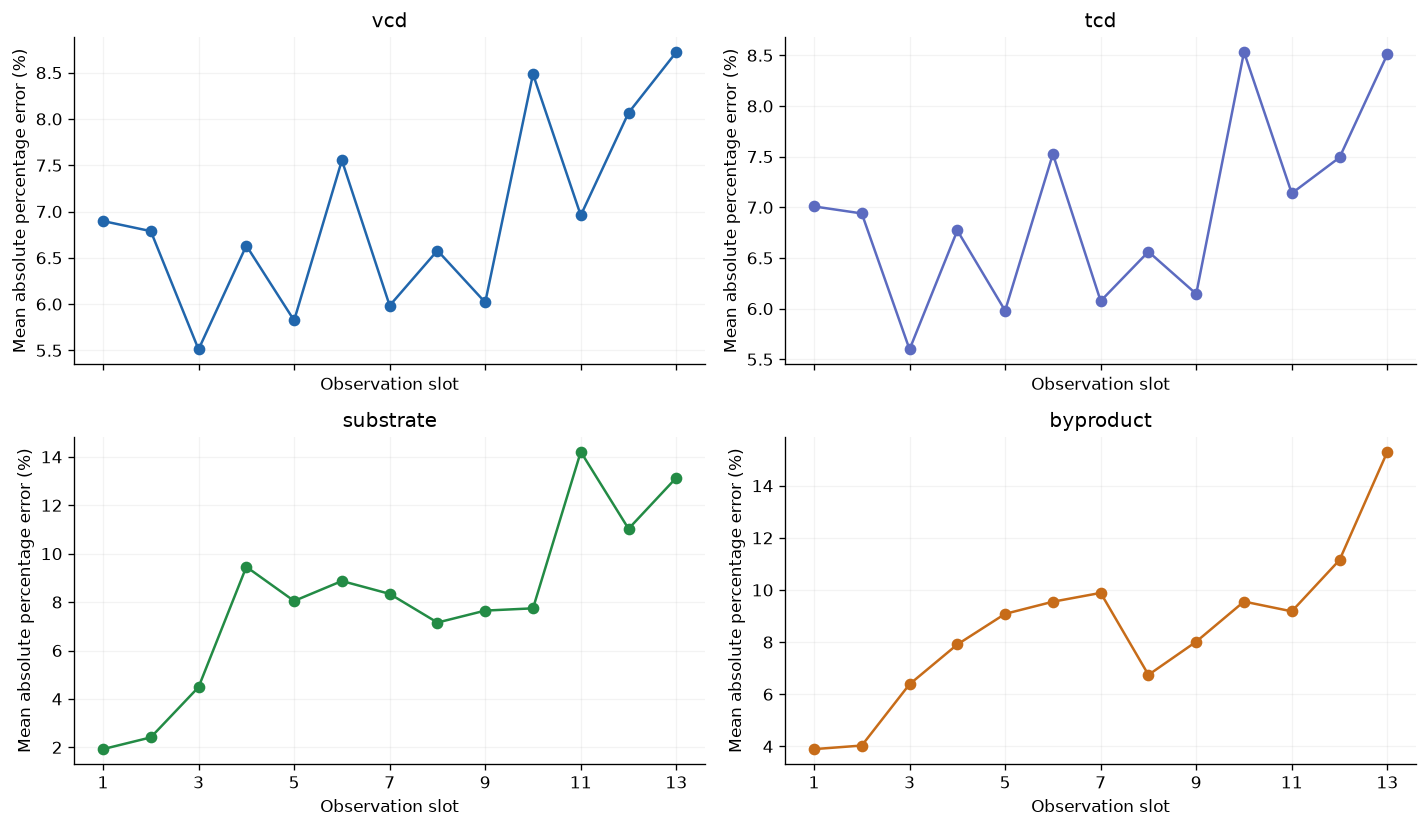

,ape_vcd,ape_tcd,ape_substrate,ape_byproduct,mean_ape
batch_id,,,,,
Batch21,15.501,15.948,13.296,9.237,13.496
Batch36,9.051,8.746,5.239,22.557,11.398
Batch42,7.861,7.404,21.481,7.106,10.963
Batch9,11.257,11.385,5.254,15.038,10.734
Batch44,6.428,6.863,16.197,11.992,10.370
Batch37,5.915,5.528,4.286,25.721,10.363
Batch47,11.798,11.708,4.241,10.992,9.685
Batch41,9.298,10.343,9.559,9.092,9.573


,batch_id,slot,true_byproduct,pred_byproduct,ape_byproduct
376,Batch34,13,1.707,0.479,71.927
324,Batch29,13,1.859,0.609,67.246
388,Batch36,12,0.313,0.493,57.285
387,Batch36,11,0.392,0.594,51.406
42,Batch4,4,1.788,2.567,43.531
44,Batch4,6,1.689,2.404,42.349


In [23]:
errors = 100 * np.abs(oof - truth) / truth
evaluation = training_queries.reset_index(drop=True).copy()
evaluation["fold"] = fold_numbers
for j, target in enumerate(TARGETS):
    evaluation["true_" + target] = truth[:, j]
    evaluation["pred_" + target] = oof[:, j]
    evaluation["ape_" + target] = errors[:, j]
evaluation["mean_ape"] = errors.mean(axis=1)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, target in zip(axes.flat, TARGETS):
    stage_error = evaluation.groupby("slot")["ape_" + target].mean()
    ax.plot(stage_error.index, stage_error.values, marker="o", color=COLORS[target])
    ax.set(title=target, xlabel="Observation slot", ylabel="Mean absolute percentage error (%)",
           xticks=[1, 3, 5, 7, 9, 11, 13])
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()

batch_errors = evaluation.groupby("batch_id")[["ape_" + t for t in TARGETS] + ["mean_ape"]].mean()
display(batch_errors.sort_values("mean_ape", ascending=False).head(8).round(3))
display(evaluation.nlargest(6, "ape_byproduct")[["batch_id", "slot", "true_byproduct", "pred_byproduct", "ape_byproduct"]].round(3))


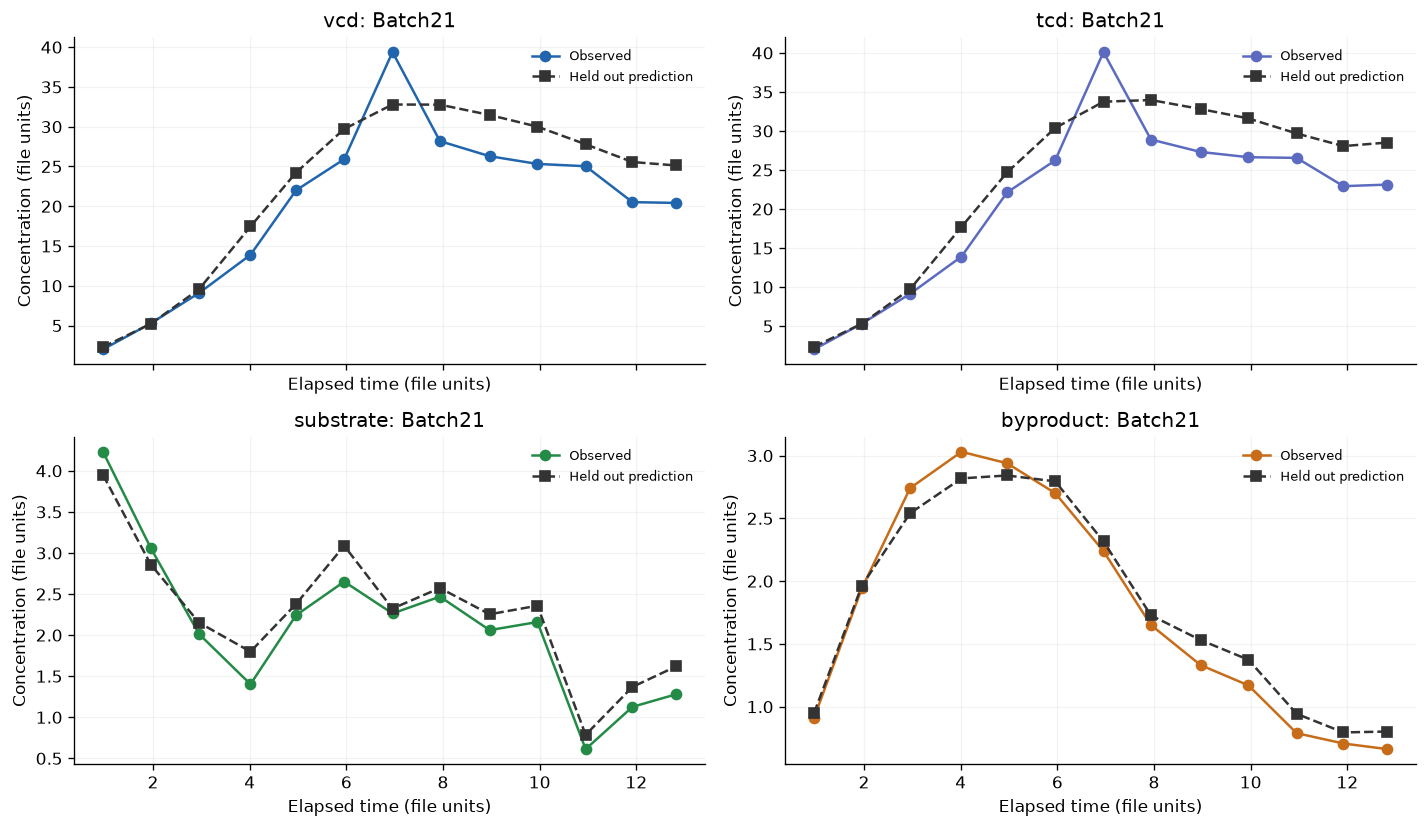

Approximate batch bootstrap interval for mean validation MAPE: 7.033% to 8.176%
This measures batch sampling variability of the existing validation predictions.
It does not include model selection uncertainty or guarantee the hidden leaderboard score.


In [24]:
worst_batch = batch_errors.mean_ape.idxmax()
case = evaluation.loc[evaluation.batch_id.eq(worst_batch)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, target in zip(axes.flat, TARGETS):
    ax.plot(case.elapsed_time, case["true_" + target], "o-", color=COLORS[target], label="Observed")
    ax.plot(case.elapsed_time, case["pred_" + target], "s--", color="#333333", label="Held out prediction")
    ax.set(title=f"{target}: {worst_batch}", xlabel="Elapsed time (file units)", ylabel="Concentration (file units)")
    ax.grid(alpha=.15)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

# Resample whole batches rather than treating 637 correlated rows as independent.
rng = np.random.default_rng(SEED)
batch_mean_errors = batch_errors.mean_ape.to_numpy()
resampled_means = rng.choice(batch_mean_errors, size=(3000, len(batch_mean_errors)), replace=True).mean(axis=1)
interval = np.quantile(resampled_means, [.025, .975])
print(f"Approximate batch bootstrap interval for mean validation MAPE: {interval[0]:.3f}% to {interval[1]:.3f}%")
print("This measures batch sampling variability of the existing validation predictions.")
print("It does not include model selection uncertainty or guarantee the hidden leaderboard score.")


## 8. Fit all complete batches and generate the submission

After validation, refit the chosen models using all 49 complete batches. Generate the 156 predictions in the template's original order. Biological consistency checks are applied to both validation and final predictions.

The exported timestamp strings are copied from the template, so the data engineering fix cannot change the submission keys. The numeric prediction table remains available for the optional API call.


In [25]:
final_cells = SharedCurveRegressor(n_knots=12, alpha=.01, robust_cutoff=.05).fit(raw, train_ids)
final_substrate = IntervalMetaboliteModel(n_estimators=N_TREES, min_samples_leaf=1).fit(interval_train, truth[:, 2])
final_byproduct = ByproductCurve(n_knots=12, alpha=30, robust_cutoff=.1, phase=True).fit(raw, train_ids)

predictions = np.empty((len(template), 4))
predictions[:, :2] = final_cells.predict(public_inputs, hidden_queries)[["vcd", "tcd"]].to_numpy()
predictions[:, 2] = final_substrate.predict(interval_hidden)
predictions[:, 3] = final_byproduct.predict(public_inputs, hidden_queries)
consistency_adjustments = int(np.sum(predictions[:, 1] < predictions[:, 0]))
predictions[:, 1] = np.maximum(predictions[:, 1], predictions[:, 0])

submission = template.copy()
submission[TARGETS] = predictions
assert submission.shape == (156, 6)
assert list(submission.columns) == list(template.columns)
pd.testing.assert_frame_equal(submission[["batch_id", "elapsed_time"]], template[["batch_id", "elapsed_time"]])
assert np.isfinite(submission[TARGETS].to_numpy()).all()
assert submission[TARGETS].gt(0).all().all()
assert submission.tcd.ge(submission.vcd).all()

export_table = template_text.copy()
export_table[TARGETS] = predictions
submission_path = OUTPUT_DIR / "submission.csv"
export_table.to_csv(submission_path, index=False)
read_back = pd.read_csv(submission_path, dtype={"batch_id": str, "elapsed_time": str})
pd.testing.assert_frame_equal(read_back[["batch_id", "elapsed_time"]], template_text[["batch_id", "elapsed_time"]])
assert np.allclose(read_back[TARGETS], predictions, rtol=1e-12, atol=1e-12)

evaluation.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
score_table.to_csv(OUTPUT_DIR / "validation_scores.csv")
metrics = {"evaluation": "fivefold whole-batch cross validation",
           "complete_batches": len(train_ids), "hidden_batches": len(hidden_ids),
           "prediction_rows": len(submission), "mape_percent": dict(zip(TARGETS, model_scores.tolist())),
           "mean_mape_percent": float(model_scores.mean()),
           "baseline_mean_mape_percent": float(baseline_scores.mean()),
           "bootstrap_interval_percent": interval.tolist(),
           "leaderboard_submitted": False,
           "selection_note": "Model design was developed on the same 49 complete batches.",
           "recording_transcribed": False}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(f"Saved {len(submission)} predictions to {submission_path}")
print("Cell consistency adjustments:", consistency_adjustments)
display(submission.head(10).round(5))


Saved 156 predictions to results/submission.csv
Cell consistency adjustments: 0


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct
0,Batch5,0.96597,2.48550,2.52548,3.96857,0.95569
1,Batch5,1.94861,5.60245,5.67319,2.82119,1.88418
2,Batch5,2.94028,10.28684,10.40160,2.10087,2.35007
3,Batch5,3.91944,17.96884,18.14595,1.95925,2.48906
4,Batch5,4.92431,25.79279,26.17556,2.30197,2.42519
5,Batch5,5.91667,31.70957,32.28687,3.03481,2.30282
6,Batch5,6.95278,35.44792,36.35280,2.34645,1.82938
7,Batch5,7.94514,35.21668,36.39664,2.52176,1.30069
8,Batch5,8.94097,33.78816,35.09863,2.33032,1.11556
9,Batch5,9.93819,32.43278,34.04796,2.40587,0.96881


### Inspect one hidden batch prediction

These are model outputs, not observed hidden biology. Plotting them catches gross discontinuities, impossible signs or incorrect row alignment before submission.


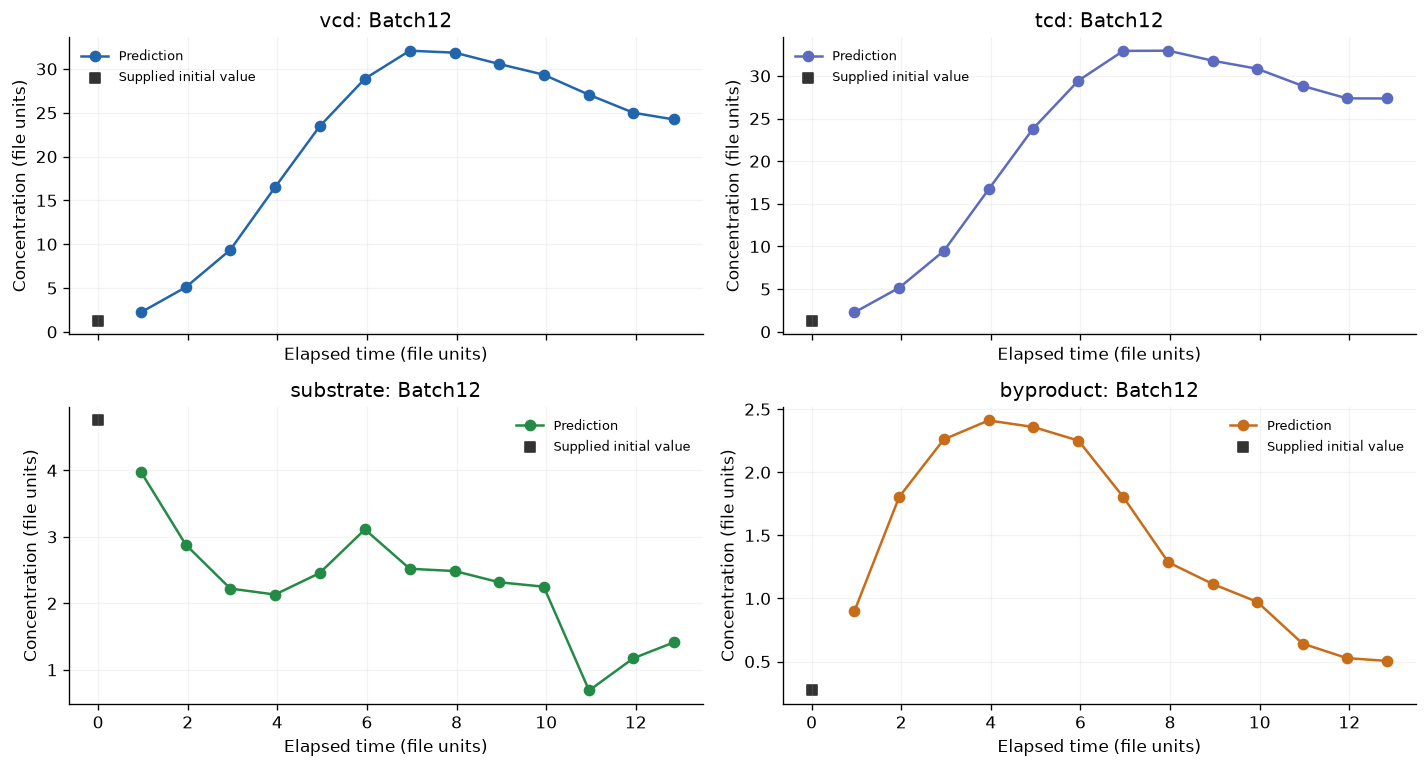

In [26]:
hidden_example = hidden_ids[0]
case = submission.loc[submission.batch_id.eq(hidden_example)]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, target in zip(axes.flat, TARGETS):
    ax.plot(case.elapsed_time, case[target], "o-", color=COLORS[target], label="Prediction")
    ax.scatter([0], [initial.loc[hidden_example, target]], color="#333333", marker="s", label="Supplied initial value")
    ax.set(title=f"{target}: {hidden_example}", xlabel="Elapsed time (file units)", ylabel="Concentration (file units)")
    ax.grid(alpha=.15)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## 9. Explain what the fitted models learned

The cell model's coefficients describe changes in log concentration per one training standard deviation of a batch feature, after the other predictors are included. These are conditional associations. Correlated feeds can redistribute their coefficients, so the chart is not a causal ranking.

The substrate chart averages the forests' feature importances across observation slots. This is a descriptive training diagnostic. It does not establish that changing the highest ranked feed would improve the culture.


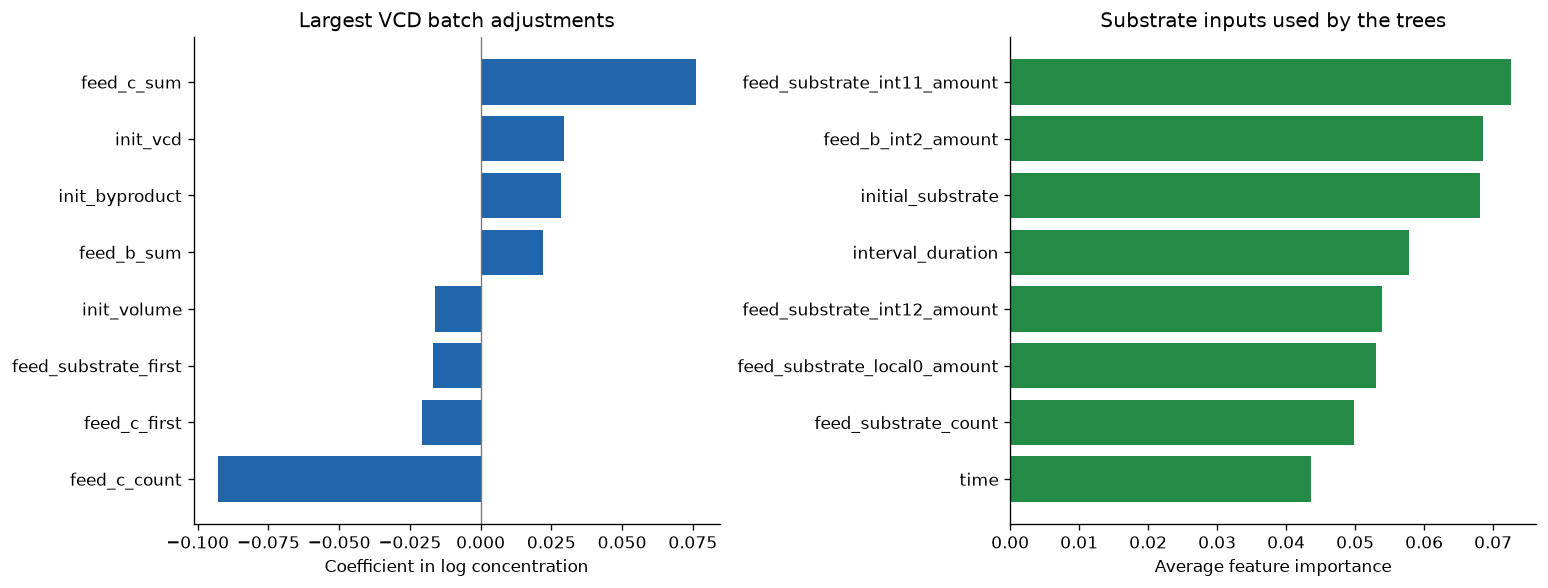

In [27]:
n_batch_features = len(final_cells.feature_names)
cell_coefficients = pd.Series(final_cells.models["vcd"].coef_[-n_batch_features:], index=final_cells.feature_names)
top_cell = cell_coefficients.reindex(cell_coefficients.abs().nlargest(8).index).sort_values()
substrate_importance = pd.Series(np.mean([m.feature_importances_ for m in final_substrate.models_.values()], axis=0),
                                 index=final_substrate.columns_).nlargest(8).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top_cell.index, top_cell.values, color="#2166ac")
axes[0].axvline(0, color="#777777", linewidth=.8)
axes[0].set(title="Largest VCD batch adjustments", xlabel="Coefficient in log concentration")
axes[1].barh(substrate_importance.index, substrate_importance.values, color="#238b45")
axes[1].set(title="Substrate inputs used by the trees", xlabel="Average feature importance")
fig.tight_layout()
plt.show()


## 10. Optional leaderboard submission

This follows the endpoint and JSON structure supplied in the organizer's notebook. It does not run automatically. Enter the correct team name, provide a token through `BIOREACTOR_TOKEN` if the organizer requires one, and enable submission only when you intend to send the predictions.

No token is written to the notebook. A successful response is the first point at which an actual leaderboard score can be reported.


In [ ]:
import base64
import urllib.request
import urllib.error

BASE_URL = "https://leaderboard-project1-runai-innovation-thibaut.inference.compute.datascience.ch/api/v1"
ENABLE_SUBMISSION = False
TEAM_NAME = "Team XX"

def submit_predictions(frame, team_name, token=""):
    if team_name == "Team XX" or not team_name.strip():
        raise ValueError("Set your actual competition team name first.")
    payload = json.dumps({"predictions": frame.to_dict(orient="records")}, allow_nan=False).encode("utf-8")
    authorization = base64.b64encode(f"{team_name}:{token}".encode("utf-8")).decode("ascii")
    request = urllib.request.Request(BASE_URL + "/submit", data=payload, method="POST",
        headers={"Content-Type": "application/json", "Authorization": "Basic " + authorization})
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            return json.load(response)["metrics"]
    except urllib.error.HTTPError as error:
        raise RuntimeError(f"Leaderboard returned HTTP {error.code}: {error.read().decode('utf-8')}") from error

if ENABLE_SUBMISSION:
    leaderboard_metrics = submit_predictions(submission, TEAM_NAME, os.environ.get("BIOREACTOR_TOKEN", ""))
    display(leaderboard_metrics)
else:
    print("Submission is disabled. The validated CSV is ready for your team.")


## 11. Notes

1. We recognized that the dataset is an asynchronous event log. We separated biological observations from interventions instead of replacing missing measurements with zeros.
2. We checked the prediction contract and used the same available information in validation as in the hidden batches.
3. We found a timestamp precision mismatch that would break a naive submission join, then verified every prediction key.
4. We used biology to guide feature engineering: viability, dilution, feeding intervals and changes with process stage.
5. We discovered that feed totals do not fully explain measured volume. The unexplained difference became an empirical predictor, with its physical interpretation left open.
6. We started with a median trajectory, then used compact target-specific models and validated on complete unseen batches.
7. We inspected weak cases and retained unusual measurements in scoring. We report local validation separately from the leaderboard.

### What would improve the next iteration most?

Confirm the feed units, feed identities, operating mode and whether the supplied future schedules are planned or recorded control actions. Obtain the briefing transcript. These details could justify a better material balance or a mechanistic model. Additional independent runs would also make model selection more reliable.

The current files support a useful statistical solution. They do not support a guaranteed large leaderboard margin or a unique mechanistic explanation for every correlation.

## Sources and reproducibility

The two supplied CSV files are the sole source of training and prediction data. Their SHA256 hashes are recorded in section 1. The supplied `Leaderboard_template(1).ipynb` is the source of the API endpoint and submission format. The leaderboard benchmark values come from the user's message.

1. [Beckman Coulter: cell counting, cell concentration and viability definitions](https://www.beckman.com/resources/techniques-and-methods/cell-counting)
2. [Merck: cell culture monitoring and observed dilution after feed additions](https://www.merckmillipore.com/TN/fr/technical-documents/technical-article/pharmaceutical-and-biopharmaceutical-manufacturing/in-line-real-time-monitoring-cho-cell-culture-raman)
3. [scikit-learn: mean absolute percentage error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_percentage_error.html)
4. [scikit-learn: validation with nonoverlapping groups](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)
5. [scikit-learn: spline features](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html)
6. [scikit-learn: ExtraTrees regression](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html)
